In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans 
from sklearn.preprocessing import StandardScaler

In [5]:
df = pd.read_csv(r"C:\Users\Pavan Patil\Downloads\archive (1)\Mall_Customers.csv")
print(df.head())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [8]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values
print("Dataset shape:", X.shape)

Dataset shape: (200, 2)


In [9]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [10]:
inertia = []

for k in range(1, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(X_scaled)

    inertia.append(model.inertia_)

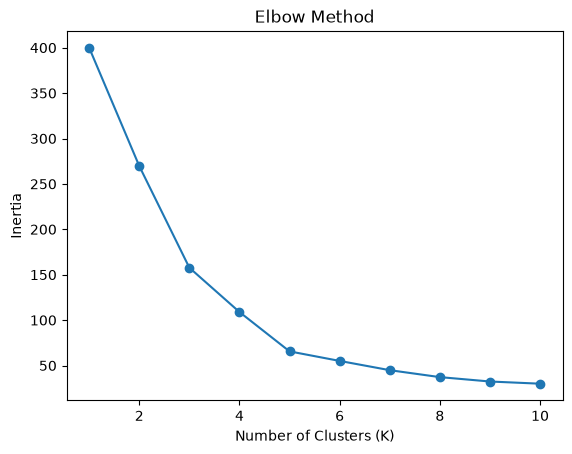

In [11]:
plt.plot(range(1, 11), inertia, marker='o')

plt.xlabel("Number of Clusters (K)")

plt.ylabel("Inertia")

plt.title("Elbow Method")

plt.show()

In [12]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

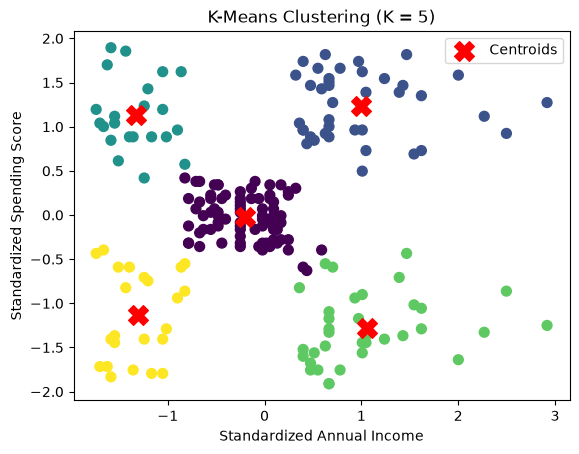

In [13]:
plt.scatter(

    X_scaled[:, 0], X_scaled[:, 1],

    c=clusters, cmap='viridis', s=50

)

plt.scatter(

    kmeans.cluster_centers_[:, 0],

    kmeans.cluster_centers_[:, 1],

    marker='X', s=200, color='red', label='Centroids'

)

plt.xlabel("Standardized Annual Income")

plt.ylabel("Standardized Spending Score")

plt.title("K-Means Clustering (K = 5)")

plt.legend()

plt.show()

In [14]:
print("\nFirst 10 cluster assignments:")

print(clusters[:10])


First 10 cluster assignments:
[4 2 4 2 4 2 4 2 4 2]
